# Bahrain telemetry case study

Telemetry here means the car data sampled during a lap, such as speed and throttle against time. I cut each clean lap into 25 mini-sectors of equal relative distance. The time spent in each mini-sector comes from interpolating elapsed lap time against distance, where distance is integrated from speed. The times are then rescaled so they add up to the official lap time. Fitting the M1 model to each mini-sector's time shows where on the lap the fitted degradation rate shows up.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import config as cfg
import f1deg as F
pd.set_option("display.width", 160)
COL = {"SOFT": "#c0392b", "MEDIUM": "#d4a017", "HARD": "#555555"}

q = pd.read_csv("results/telemetry_quality.csv")
fits = pd.read_csv("results/minisector_fits.csv")
cvs = pd.read_csv("results/corner_vs_straight.csv")
lin = pd.read_csv("results/linearity_check.csv")
print(q.round(4).to_string(index=False))

 clean_laps  kept  dropped  mismatch_mean  mismatch_median  mismatch_max
        951   945        6         0.3127            0.293         1.123


## Data quality
Laps with a mismatch above the limit between summed mini-sector time and the official lap time were dropped. The mean, median and maximum mismatch in the table are over all clean laps that were checked, including the dropped ones.

## Speed trace
The figure compares the second clean lap and the last clean lap of the longest stint. The difference mixes fuel burn and tyre wear. It is shown for illustration only.

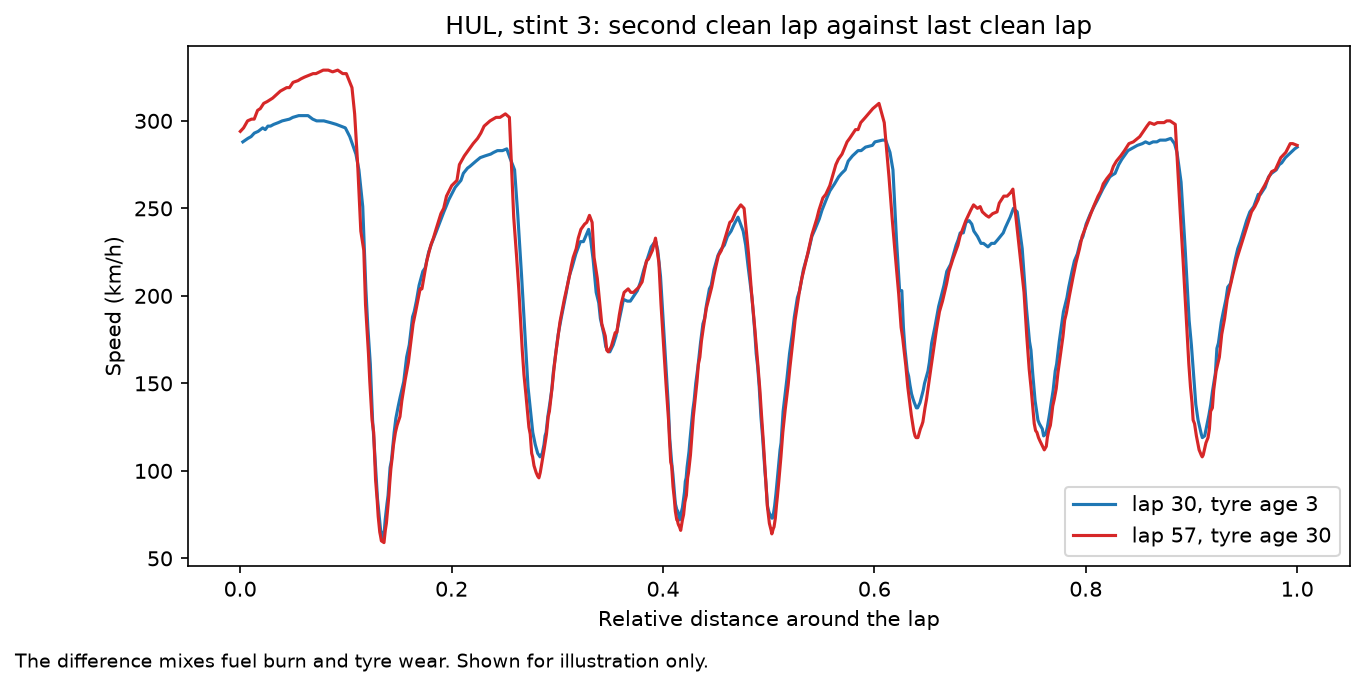

In [2]:
from IPython.display import Image, display
display(Image("Images/speed_trace_early_vs_late.png"))

## Degradation by mini-sector

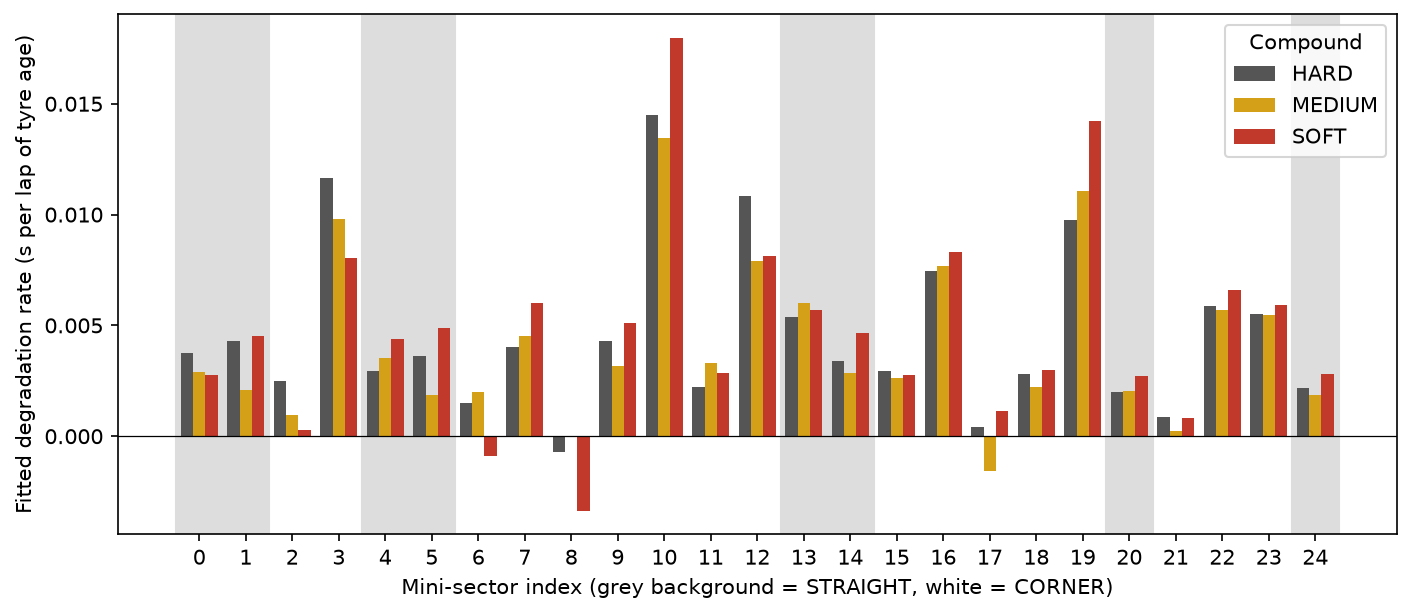

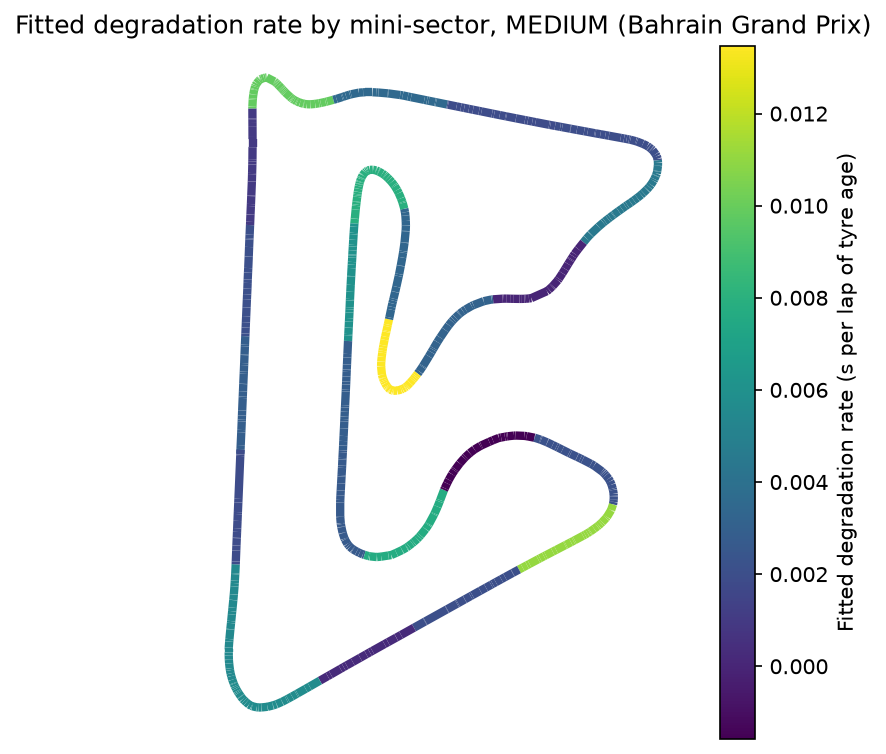

In [3]:
display(Image("Images/minisector_deg_bar.png"))
display(Image("Images/track_deg_map.png"))

## Corner against straight
A mini-sector is STRAIGHT if the reference lap kept throttle at 95 percent or more throughout it. Otherwise it is CORNER.

In [4]:
print(cvs.round(4).to_string(index=False))

compound  total_rate  corner_rate  straight_rate  corner_share  straight_share  ref_time_share_corner  ref_time_share_straight  n_corner_minisectors  n_straight_minisectors
    HARD      0.1141       0.0865         0.0276        0.7583          0.2417                 0.7535                   0.2465                    17                       8
  MEDIUM      0.1016       0.0785         0.0231        0.7727          0.2273                 0.7535                   0.2465                    17                       8
    SOFT      0.1193       0.0868         0.0325        0.7278          0.2722                 0.7535                   0.2465                    17                       8


In each compound the share of fitted degradation from corner mini-sectors is close to the share of lap time spent in corner mini-sectors. For SOFT the corner share is a little below the time share. For HARD and MEDIUM it is slightly above. With one race, three compounds and mini-sector edges that shift from lap to lap, these differences are small observations.

## Linearity check
Because the mini-sector times add up to the lap time, the mini-sector rates must add up to the lap-time rate. This is asserted in `run_telemetry.py` to a tolerance of 1e-6.

In [5]:
lin["abs_difference"] = (lin["sum_of_minisectors"] - lin["lap_time_fit"]).abs()
print(lin.to_string(index=False))
print("max abs difference:", lin["abs_difference"].max())

 compound  sum_of_minisectors  lap_time_fit  abs_difference
     HARD            0.114117      0.114117    9.714451e-17
   MEDIUM            0.101607      0.101607    9.020562e-16
     SOFT            0.119299      0.119299    7.077672e-16
LapNumber           -0.061646     -0.061646    2.983724e-16
max abs difference: 9.020562075079397e-16


## What this shows and what it does not
In this race, about three quarters of the fitted degradation sits in corner mini-sectors, which is about the share of lap time spent there. So the fitted rate is not concentrated in corners beyond their share of the lap. The case study is one race, so it is not evidence about other circuits. The fitted rate still mixes tyre wear with anything else that grows with tyre age, and mini-sector times come from integrated speed with some error.